<a href="https://colab.research.google.com/github/karsarobert/DeepLearning2026/blob/main/PTE_DL8_TL_javitott.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CNN finomhangolás

Az ImageNet adathalmaz több mint 1 millió gyakorló képből áll.

**Mi van, ha nincs túl sok képünk?**
 1. menjünk és gyűjtsünk sokkal több adatot
 2. használjuk az ImageNet adathalmazból tanult tudást

Az 1 millió ImageNet-képen betanított neurális hálózat használatával **jó belső reprezentációval** kell rendelkeznie (kerek tárgyak, szemek, szöveg stb. megtalálása) a különböző tárgyak fotóihoz. A transzfer tanulás lényege, hogy ezekre a reprezentációkra támaszkodunk.

Általánosságban a transzfer tanulás során azt szeretnénk, hogy minél több információ kerüljön át az egyik adatkészletből a másikba. Mivel az első rétegek általánosak, nem kell sokat változniuk, így jóval alacsonyabb tanulási sebesség is megfelel. Az utolsó rétegek feladatspecifikusabbak, így ezeket jobban kell képeznünk (magasabb tanulási rátával).


In [ ]:
# Ellenőrizzük a TensorFlow és a GPU elérhetőségét (a %tensorflow_version 2.x már elavult)
import tensorflow as tf
print("TensorFlow verzió:", tf.__version__)
print("Elérhető GPU-k:", tf.config.list_physical_devices('GPU'))


TensorFlow verzió: 2.21.0
Elérhető GPU-k: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
from PIL import Image
from pathlib import Path
import numpy as np
import tensorflow as tf
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Input
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import kagglehub


# Kutyák és macskák

A Kaggle "Kutyák és macskák" verseny adatait fogjuk használni. A dolgok megnehezítése érdekében a gyakorló képek egy apró részhalmazára korlátozódunk, 300 képre a kutyák és 300 képre a macskák esetében.

<img src="https://storage.googleapis.com/kaggle-media/competitions/kaggle/3362/media/woof_meow.jpg">

https://www.kaggle.com/c/dogs-vs-cats/

Az ImageNet előre betanított modelljei tökéletes választásnak tűnnek, mivel az ImageNet több mint 100 különböző kutyafajtát tartalmaz, így a hálózat súlyainak kivételesnek kell lenniük a kutyák osztályozásakor.



In [ ]:
# Előkészített adathalmaz letöltése (--id kapcsoló nélkül, az új gdown szintaxis szerint)
!gdown 1Gj4T1NIThIx_Py4hd2YbAGpVJhpUlCVK


Downloading...
From (original): https://drive.google.com/uc?id=1Gj4T1NIThIx_Py4hd2YbAGpVJhpUlCVK
From (redirected): https://drive.google.com/uc?id=1Gj4T1NIThIx_Py4hd2YbAGpVJhpUlCVK&confirm=t&uuid=cb5e84f4-0252-40fe-8be8-6c8f0438c685
To: /content/dogscats.zip
100% 572M/572M [00:09<00:00, 59.2MB/s]


In [ ]:
# unzip it
!unzip -q dogscats.zip

In [ ]:
train_dogs = list(Path('train/dog/').glob('*'))
train_cats = list(Path('train/cat/').glob('*'))

print(f'#Training images: {len(train_cats), len(train_dogs)}')

test_dogs = list(Path('test/dog/').glob('*'))
test_cats = list(Path('test/cat/').glob('*'))

print(f'#Test images: {len(test_cats), len(test_dogs)}')

#Training images: (300, 300)
#Test images: (12200, 12200)


### A képek többsége korrekt, de néhány kép problémás lehet!

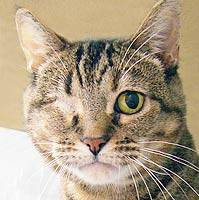

In [ ]:
Image.open('train/cat/cat.11368.jpg')

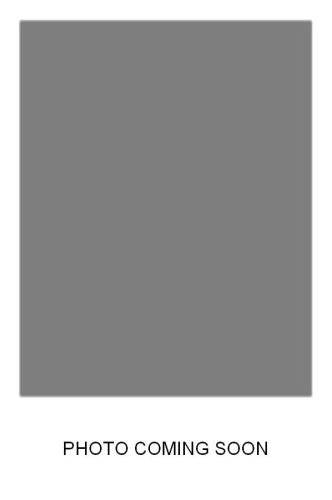

In [ ]:
Image.open('train/cat/cat.11184.jpg')

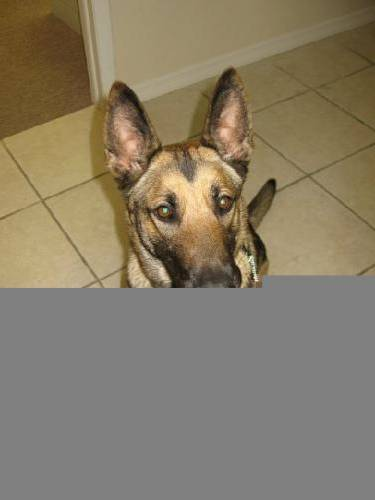

In [ ]:
Image.open('train/dog/dog.11191.jpg')

### Modell létrehozása (Kaggle Models / Keras Applications)

A ResNet50 architektúrát fogjuk használni, és két modellt hasonlítunk össze:
 1. **Véletlenszerűen inicializált** (`weights=None`)
 2. **ImageNet-en előre betanított** (letöltve a Kaggle Models-ről / Keras Applications-ből)

Mivel az ImageNet 1000 kategóriát tartalmaz, a legfelső osztályozó réteget (`include_top=False`) elhagyjuk, és saját fejet építünk rá 1 neuronnal (bináris osztályozás: 0 = macska, 1 = kutya).
 - **Veszteségfüggvény:** bináris keresztentrópia (`binary_crossentropy`)
 - **Aktiváció:** `sigmoid` a `softmax` helyett (egyetlen kimeneti neuronra alkalmazott softmax mindig konstans 1.0-t adna!)


In [ ]:
# 1. Véletlenszerűen inicializált alapmodell
base_model = ResNet50(weights=None, include_top=False, input_shape=(224, 224, 3))

# 2. Előre betanított alapmodell (Kaggle Models / ImageNet súlyokkal)
# Megjegyzés: Kaggle környezetben vagy keras_hub használatakor közvetlenül a Kaggle-ről is betölthető:
# weights_path = kagglehub.model_download('keras/resnetv2/keras/resnet50_v2_imagenet')
base_pretrained_model = ResNet50(weights='imagenet', include_top=False, input_shape=(224, 224, 3))


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


In [ ]:
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(1024, activation='relu')(x)
predictions = Dense(1, activation='sigmoid')(x)

model = Model(inputs=base_model.input, outputs=predictions, name='ResNet50_From_Scratch')


### Az előre betanított modell felépítése és helyes befagyasztása


1. **Befagyasztás (`base_pretrained_model.trainable = False`)
2. **BatchNormalization védelem (`training=False`):** Amikor előtanított ResNet-et használunk, a bázismodell hívásakor meg kell adni a `training=False` argumentumot (`base_pretrained_model(inputs, training=False)`), különben a `BatchNormalization` rétegek felülírják az ImageNet-en tanult mozgóátlagokat!


In [ ]:
# Először befagyasztjuk a konvolúciós bázist
base_pretrained_model.trainable = False

# Functional API-val felépítjük a modellt úgy, hogy a base_pretrained_model inference módban (training=False) fusson
inputs = Input(shape=(224, 224, 3))
x = base_pretrained_model(inputs, training=False)
x = GlobalAveragePooling2D()(x)
x = Dense(1024, activation='relu')(x)
predictions = Dense(1, activation='sigmoid')(x)

pretrained_model = Model(inputs=inputs, outputs=predictions, name='ResNet50_Pretrained')


Ellenőrizzük a tanítható rétegeket: most már mind a `Dense(1024)`, mind a kimeneti `Dense(1)` réteg tanítható (`trainable = True`), míg a `resnet50` bázis befagyasztva marad.

In [ ]:
for layer in pretrained_model.layers:
    print(f"{layer.name:25s} | Trainable: {layer.trainable}")


input_layer_2             | Trainable: True
resnet50                  | Trainable: False
global_average_pooling2d_1 | Trainable: True
dense_2                   | Trainable: True
dense_3                   | Trainable: True


Nézzük meg mindkét modellt!

In [ ]:
model.summary()

Model: "ResNet50_From_Scratch"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 25,686,913 (97.99 MB)

 Trainable params: 25,633,793 (97.79 MB)

 Non-trainable params: 53,120 (207.50 KB)

In [ ]:
pretrained_model.summary()

Model: "ResNet50_Pretrained"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1024)           │     2,098,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │         1,025 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,686,913 (97.99 MB)

 Trainable params: 2,099,201 (8.01 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

## Dataloader

Korábban csak betöltöttük az összes adatot a memóriába, és adtuk át a neurális hálózatnak. Nagyobb datset esetén gyakran előfordul, hogy egyszerűen nem fér el a RAM-ban. A datagenerátorok olyan függvények, amelyek egyszerre egy adag adatot szolgáltatnak.

A Tf-keras rendelkezik egy beépített ImageDataGeneratorral, itt ezt fogjuk használni. A képnövelés a dataloader-en belül is elvégezhető.

A kategóriákat a mappanevekből illesztjük össze.

In [ ]:
# A kézi imagenet_convert függvény helyett/mellett használhatjuk a Keras beépített preprocess_input függvényét is,
# amely pontosan ugyanezt végzi el (RGB -> BGR konverzió és az ImageNet csatornaátlagok [103.939, 116.779, 123.68] levonása):
def imagenet_convert(img):
    return preprocess_input(img.astype(np.float32))


In [ ]:
# adatbővítés (Data Augmentation) ResNet50-hez:
train_datagen_aug = ImageDataGenerator(
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    preprocessing_function=imagenet_convert
)


In [ ]:
train_datagen = ImageDataGenerator(preprocessing_function=imagenet_convert)
test_datagen  = ImageDataGenerator(preprocessing_function=imagenet_convert)

train_generator = train_datagen.flow_from_directory(
    'train',
    target_size=(224, 224),
    batch_size=16,
    class_mode='binary'
)

test_generator = test_datagen.flow_from_directory(
    'test',
    target_size=(224, 224),
    batch_size=16,
    class_mode='binary',
    shuffle=False
)


Found 600 images belonging to 2 classes.
Found 24400 images belonging to 2 classes.


Állítsuk össze a modelleket az Adam optimalizálóval $10^{-4}$ tanulási rátával.

In [ ]:
model.compile(optimizer=Adam(learning_rate=1e-4),loss='binary_crossentropy',metrics=['accuracy'])
pretrained_model.compile(optimizer=Adam(learning_rate=1e-4),loss='binary_crossentropy',metrics=['accuracy'])

### A modelleket 25 korszakon keresztül képezzük, és minden 5. korszak után elvégezzük el a validálást.

A képzési idő elég alacsony egy korszak esetében, a validálás azonban sokkal lassabb. Ez azért történik, mert 40x több képet kell validálnunk, mint amennyit a képzéshez használunk.

In [ ]:
history_scratch = model.fit(
    train_generator,
    validation_data=test_generator,
    validation_freq=5,
    epochs=25
)


Epoch 1/25
38/38 ━━━━━━━━━━━━━━━━━━━━ 112s 1s/step - accuracy: 0.5717 - loss: 0.9752
Epoch 2/25
38/38 ━━━━━━━━━━━━━━━━━━━━ 7s 176ms/step - accuracy: 0.5517 - loss: 0.7491
Epoch 3/25
38/38 ━━━━━━━━━━━━━━━━━━━━ 7s 179ms/step - accuracy: 0.6450 - loss: 0.6728
Epoch 4/25
38/38 ━━━━━━━━━━━━━━━━━━━━ 7s 184ms/step - accuracy: 0.6117 - loss: 0.7180
Epoch 5/25
38/38 ━━━━━━━━━━━━━━━━━━━━ 116s 3s/step - accuracy: 0.6750 - loss: 0.6236 - val_accuracy: 0.5007 - val_loss: 0.9817
Epoch 6/25
38/38 ━━━━━━━━━━━━━━━━━━━━ 7s 181ms/step - accuracy: 0.6617 - loss: 0.6033
Epoch 7/25
38/38 ━━━━━━━━━━━━━━━━━━━━ 7s 181ms/step - accuracy: 0.7467 - loss: 0.5576
Epoch 8/25
38/38 ━━━━━━━━━━━━━━━━━━━━ 7s 181ms/step - accuracy: 0.7033 - loss: 0.5748
Epoch 9/25
38/38 ━━━━━━━━━━━━━━━━━━━━ 7s 181ms/step - accuracy: 0.7250 - loss: 0.6399
Epoch 10/25
38/38 ━━━━━━━━━━━━━━━━━━━━ 110s 3s/step - accuracy: 0.7550 - loss: 0.5599 - val_accuracy: 0.6006 - val_loss: 0.8620
Epoch 11/25
38/38 ━━━━━━━━━━━━━━━━━━━━ 7s 180ms/step - acc

In [ ]:
history_pretrained = pretrained_model.fit(
    train_generator,
    validation_data=test_generator,
    validation_freq=5,
    epochs=25
)


Epoch 1/25
38/38 ━━━━━━━━━━━━━━━━━━━━ 16s 162ms/step - accuracy: 0.9333 - loss: 0.1829
Epoch 2/25
38/38 ━━━━━━━━━━━━━━━━━━━━ 3s 71ms/step - accuracy: 0.9933 - loss: 0.0352
Epoch 3/25
38/38 ━━━━━━━━━━━━━━━━━━━━ 3s 73ms/step - accuracy: 0.9983 - loss: 0.0149
Epoch 4/25
38/38 ━━━━━━━━━━━━━━━━━━━━ 5s 67ms/step - accuracy: 0.9983 - loss: 0.0101
Epoch 5/25
38/38 ━━━━━━━━━━━━━━━━━━━━ 106s 3s/step - accuracy: 1.0000 - loss: 0.0060 - val_accuracy: 0.9811 - val_loss: 0.0504
Epoch 6/25
38/38 ━━━━━━━━━━━━━━━━━━━━ 3s 68ms/step - accuracy: 1.0000 - loss: 0.0044
Epoch 7/25
38/38 ━━━━━━━━━━━━━━━━━━━━ 3s 66ms/step - accuracy: 1.0000 - loss: 0.0037
Epoch 8/25
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 62ms/step - accuracy: 1.0000 - loss: 0.0026
Epoch 9/25
38/38 ━━━━━━━━━━━━━━━━━━━━ 3s 71ms/step - accuracy: 1.0000 - loss: 0.0022
Epoch 10/25
38/38 ━━━━━━━━━━━━━━━━━━━━ 104s 3s/step - accuracy: 1.0000 - loss: 0.0018 - val_accuracy: 0.9818 - val_loss: 0.0492
Epoch 11/25
38/38 ━━━━━━━━━━━━━━━━━━━━ 3s 66ms/step - accuracy:

### 2. Fázis: Valódi Finomhangolás (Fine-Tuning)

Miután az újonnan hozzáadott `Dense` rétegek súlyai beálltak (Feature Extraction fázis), feloldhatjuk a `base_pretrained_model` felső konvolúciós blokkját (`conv5_block`), és egy **nagyságrendekkel kisebb tanulási rátával (`1e-5`)** tovább finomhangolhatjuk a hálót.

In [ ]:
# Feloldjuk az alapmodellt, de csak az utolsó konvolúciós blokkot (conv5_block) hagyjuk taníthatónak
base_pretrained_model.trainable = True

for layer in base_pretrained_model.layers:
    if not layer.name.startswith('conv5_block') or isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# Újrafordítás alacsonyabb tanulási rátával (1e-5), hogy ne rontsuk el az előtanított súlyokat
pretrained_model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Finomhangolás további 5 epochán keresztül
history_finetune = pretrained_model.fit(
    train_generator,
    validation_data=test_generator,
    validation_freq=5,
    epochs=5
)


Epoch 1/5
38/38 ━━━━━━━━━━━━━━━━━━━━ 22s 218ms/step - accuracy: 1.0000 - loss: 3.2017e-04
Epoch 2/5
38/38 ━━━━━━━━━━━━━━━━━━━━ 3s 77ms/step - accuracy: 1.0000 - loss: 7.1454e-05
Epoch 3/5
38/38 ━━━━━━━━━━━━━━━━━━━━ 3s 78ms/step - accuracy: 1.0000 - loss: 1.3740e-05
Epoch 4/5
38/38 ━━━━━━━━━━━━━━━━━━━━ 3s 80ms/step - accuracy: 1.0000 - loss: 2.9203e-06
Epoch 5/5
38/38 ━━━━━━━━━━━━━━━━━━━━ 112s 3s/step - accuracy: 1.0000 - loss: 1.0305e-06 - val_accuracy: 0.9818 - val_loss: 0.0806


# Összefoglaló

Mindkét hálózat idővel jobb lett, de a véletlenszerűen inicializált hálózat csak <70%-os pontosságot tudott elérni (néhány ötlettel biztosan sokkal jobbat is elérhetnénk), míg az előre betanított modell >97%-os pontosságot ért el.   
Emellett az előre betanított modell esetében a képzési idő ~50%-kal alacsonyabb volt minden korszak esetében.

https://www.kaggle.com/c/dogs-vs-cats/leaderboard   
6 évvel ezelőtt a győztes 98,9%-ot ért el, a 10. helyezett 97,9%-ot, a 30. helyezett 96,7%-ot (de egy másik tesztkészleten).

**Ezeket az eredményeket ~3 perces edzéssel értük el (a validálási időt nem számítva).**


### További fejlesztések
 - az adathalmaz megtisztítása, a tévesen címkézett képek eltávolítása
 - adatbővítés
 - tesztidő növelése
 - a tanulás ütemezése
